In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

In [2]:
# Load dataset
df = pd.read_csv("/content/email.csv")

In [3]:
# Display first 5 records
print(df.head())


  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
# Check dataset size
print("Original shape:", df.shape)

Original shape: (5573, 2)


In [5]:
# Check column names
print("Columns:", df.columns.tolist())

Columns: ['Category', 'Message']


In [6]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Category    0
Message     0
dtype: int64


In [7]:
# Clean the category column
df["Category"] = df["Category"].astype(str).str.strip().str.lower()

In [8]:
# Keep only valid labels
df = df[df["Category"].isin(["spam", "ham"])].copy()

In [9]:
# Clean the message column
df["Message"] = df["Message"].fillna("").astype(str).str.strip()

In [10]:
# Remove empty messages
df = df[df["Message"] != ""]


In [11]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)
print("\nCategory distribution:")
print(df["Category"].value_counts())

print("\nCleaning completed!")


Cleaned dataset shape: (5157, 2)

Category distribution:
Category
ham     4516
spam     641
Name: count, dtype: int64

Cleaning completed!


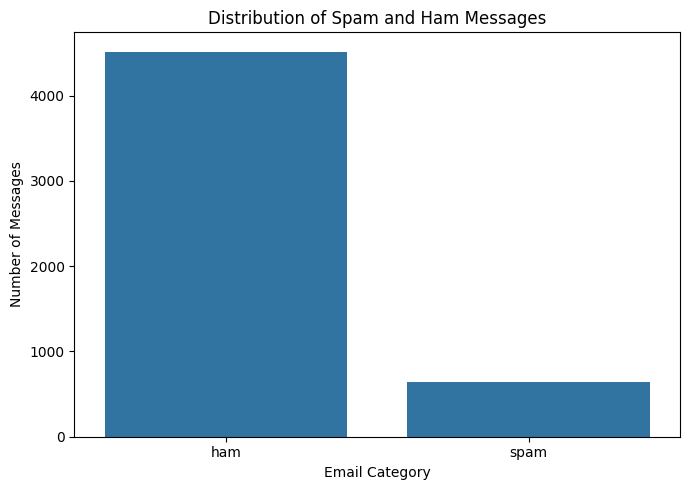

In [12]:
# Visualize the data
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Category")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Email Category")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.show()

In [13]:
# Prepare the training and testing data
from sklearn.model_selection import train_test_split

X = df["Message"]
y = df["Category"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training messages: 4125
Testing messages: 1032

Training label distribution:
Category
0    3612
1     513
Name: count, dtype: int64

Testing label distribution:
Category
0    904
1    128
Name: count, dtype: int64


Build Traditional Machine Learning Model

In [14]:
# Convert text into numbers using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

# Fit only on training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages without refitting
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4125, 10000)
Testing TF-IDF shape: (1032, 10000)


In [15]:
# train logistic Regression and naive bayes
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Naive Bayes": MultinomialNB()
}

results = {}
predictions = {}
training_times = {}

for name, model in models.items():

    start = time.time()

    model.fit(X_train_tfidf, y_train)

    training_times[name] = time.time() - start

    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    ))

print("\nTraining times:")
print(training_times)


 Logistic Regression
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.90      0.89      0.90       128

    accuracy                           0.97      1032
   macro avg       0.94      0.94      0.94      1032
weighted avg       0.97      0.97      0.97      1032


 Naive Bayes
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.70      0.82       128

    accuracy                           0.96      1032
   macro avg       0.98      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032


Training times:
{'Logistic Regression': 0.3199276924133301, 'Naive Bayes': 0.011857032775878906}


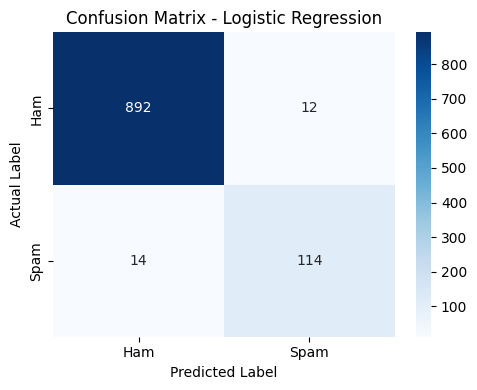

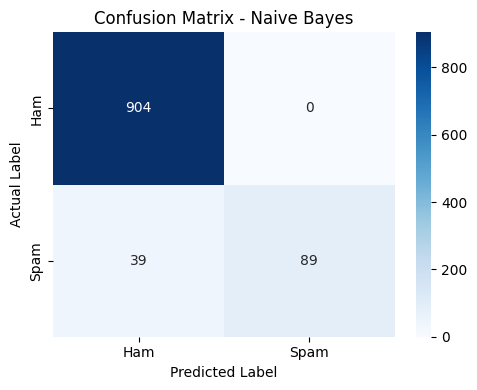

In [16]:
# create confusion matrices
for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

Build the DistillBear model

In [17]:
# Load DistilBERT and its tokenizer
import torch
from torch.utils.data import TensorDataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from sklearn.model_selection import train_test_split

MODEL_NAME = "distilbert-base-uncased"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

model.to(device)

Using device: cpu


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [18]:
# Create training, validation and test sets
X_train_bert, X_val_bert, y_train_bert, y_val_bert = (
    train_test_split(
        X_train,
        y_train,
        test_size=0.15,
        random_state=42,
        stratify=y_train
    )
)

print("Transformer training:", len(X_train_bert))
print("Transformer validation:", len(X_val_bert))
print("Final testing:", len(X_test))

Transformer training: 3506
Transformer validation: 619
Final testing: 1032


In [19]:
# Tokenize the email message
def tokenize_messages(messages):
    return tokenizer(
        messages.tolist(),
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )


train_enc = tokenize_messages(X_train_bert)
val_enc = tokenize_messages(X_val_bert)
test_enc = tokenize_messages(X_test)

y_train_tensor = torch.tensor(
    y_train_bert.to_numpy(), dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_bert.to_numpy(), dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.long
)

train_dataset = TensorDataset(
    train_enc["input_ids"],
    train_enc["attention_mask"],
    y_train_tensor
)

val_dataset = TensorDataset(
    val_enc["input_ids"],
    val_enc["attention_mask"],
    y_val_tensor
)

test_dataset = TensorDataset(
    test_enc["input_ids"],
    test_enc["attention_mask"],
    y_test_tensor
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

print("Tokenization completed!")

Tokenization completed!


In [20]:
# set the training parameters
from torch.optim import AdamW

LEARNING_RATE = 2e-5
EPOCHS = 3

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = torch.nn.CrossEntropyLoss()

print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Learning rate: 2e-05
Batch size: 16
Epochs: 3


In [21]:
# PyTrouch training loop
from sklearn.metrics import accuracy_score

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

transformer_start = time.time()

for epoch in range(EPOCHS):

    # Training phase
    model.train()
    total_train_loss = 0

    for input_ids, attention_mask, labels in train_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation phase
    model.eval()
    total_val_loss = 0
    val_preds = []
    val_actual = []

    with torch.no_grad():

        for input_ids, attention_mask, labels in val_loader:

            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(outputs.logits, labels)
            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_actual.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = accuracy_score(
        val_actual, val_preds
    )

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

transformer_train_time = time.time() - transformer_start

print("Transformer training time:",
      round(transformer_train_time, 2), "seconds")

Epoch 1/3 | Train Loss: 0.1075 | Validation Loss: 0.0244 | Validation Accuracy: 0.9952
Epoch 2/3 | Train Loss: 0.0208 | Validation Loss: 0.0254 | Validation Accuracy: 0.9919
Epoch 3/3 | Train Loss: 0.0162 | Validation Loss: 0.0213 | Validation Accuracy: 0.9935
Transformer training time: 7841.45 seconds


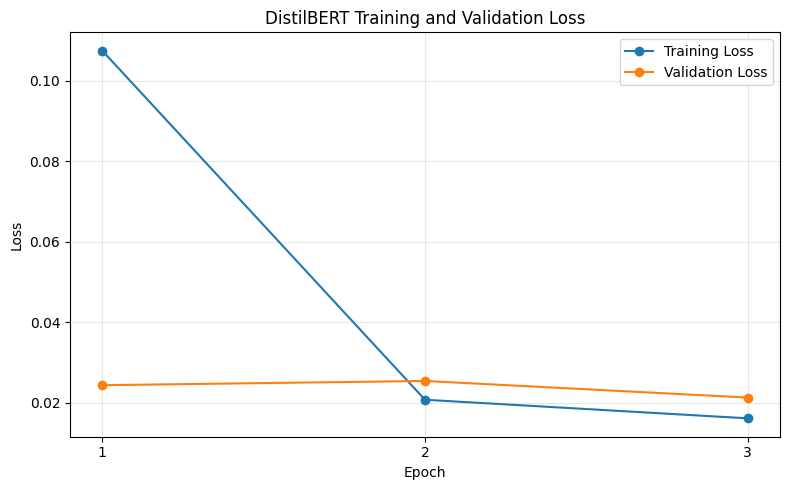

In [22]:
# Plot training behavior
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("DistilBERT Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Evaluate DistilBERT on the test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

bert_predictions = []
bert_actual = []

with torch.no_grad():

    for input_ids, attention_mask, labels in test_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        bert_predictions.extend(preds.cpu().numpy())
        bert_actual.extend(labels.numpy())

print(classification_report(
    bert_actual,
    bert_predictions,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

results["DistilBERT"] = {
    "Accuracy": accuracy_score(bert_actual, bert_predictions),
    "Precision": precision_score(
        bert_actual, bert_predictions, zero_division=0
    ),
    "Recall": recall_score(
        bert_actual, bert_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        bert_actual, bert_predictions, zero_division=0
    )
}

predictions["DistilBERT"] = np.array(bert_predictions)
training_times["DistilBERT"] = transformer_train_time

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       904
        Spam       0.95      0.92      0.94       128

    accuracy                           0.98      1032
   macro avg       0.97      0.96      0.96      1032
weighted avg       0.98      0.98      0.98      1032



Compare all three models

In [24]:
# Create a metric comparison table
results_df = pd.DataFrame(results).T

print(results_df.round(4))

results_df.to_csv(
    "model_comparison_results.csv",
    index=True
)

                     Accuracy  Precision  Recall  F1-score
Logistic Regression    0.9748     0.9048  0.8906    0.8976
Naive Bayes            0.9622     1.0000  0.6953    0.8203
DistilBERT             0.9845     0.9516  0.9219    0.9365


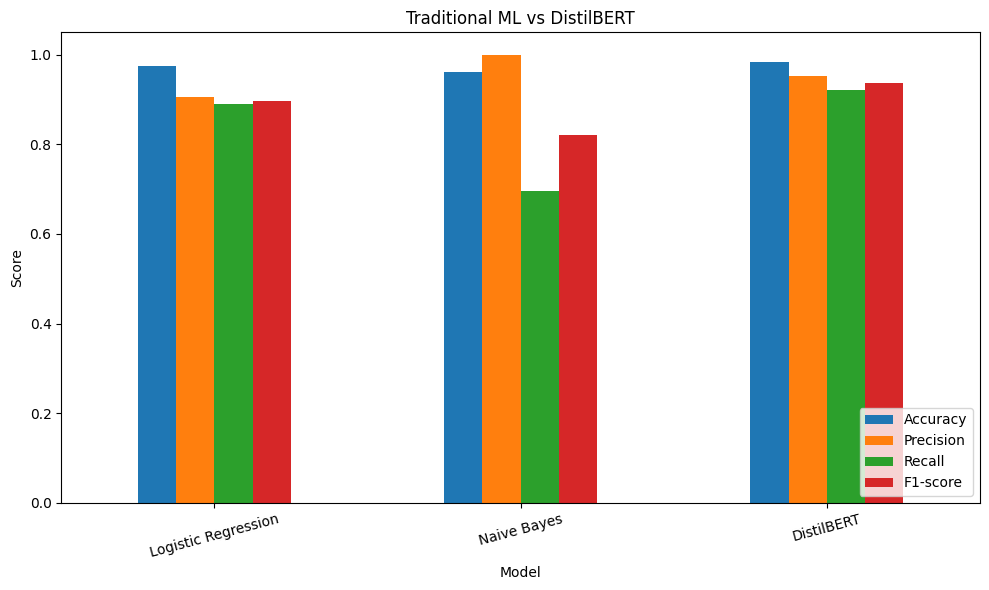

In [25]:
# visualize the metric comparison
results_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Traditional ML vs DistilBERT")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

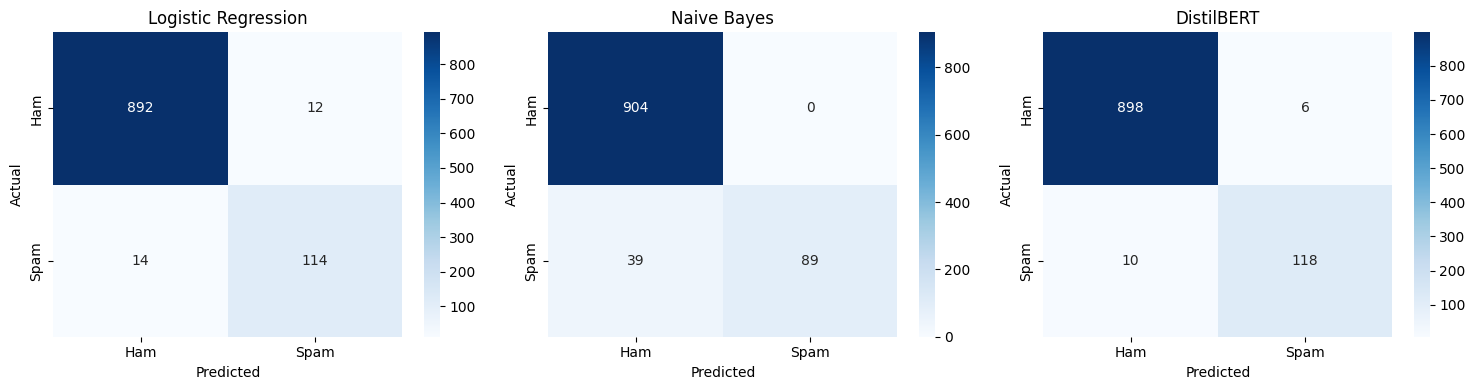

In [26]:
# compare confusion matrices
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4)
)

model_names = [
    "Logistic Regression",
    "Naive Bayes",
    "DistilBERT"
]

for ax, name in zip(axes, model_names):

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

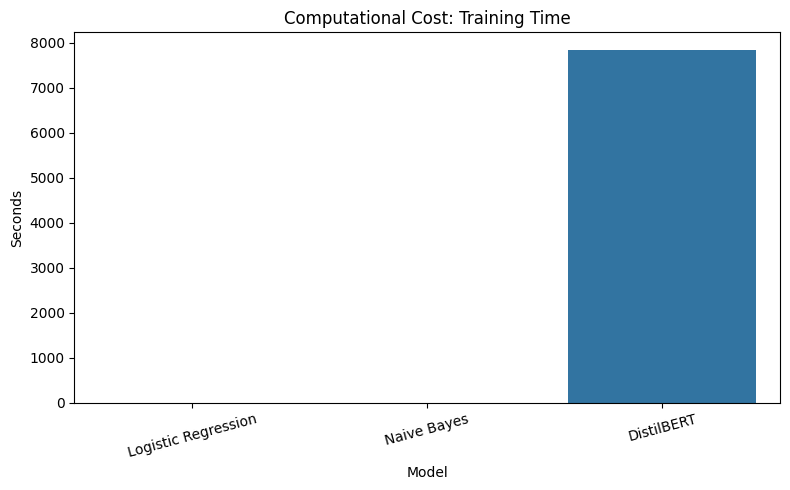

                 Model  Training Time (seconds)
0  Logistic Regression                 0.319928
1          Naive Bayes                 0.011857
2           DistilBERT              7841.452703


In [27]:
# Compare training time
time_df = pd.DataFrame({
    "Model": list(training_times.keys()),
    "Training Time (seconds)": list(training_times.values())
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=time_df,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Computational Cost: Training Time")
plt.xlabel("Model")
plt.ylabel("Seconds")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

print(time_df)

In [28]:
# Test yuor model with a new email
def predict_email(message):

    encoding = tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        padding="max_length",
        max_length=128
    )

    encoding = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    model.eval()

    with torch.no_grad():
        outputs = model(**encoding)
        prediction = torch.argmax(
            outputs.logits, dim=1
        ).item()

    return "Spam" if prediction == 1 else "Ham"


email = "Congratulations! You have won a free prize. Click now!"
print("Prediction:", predict_email(email))


Prediction: Spam


In [29]:
email = "Hi, I will call you after reaching home."
print("Prediction:", predict_email(email))

Prediction: Ham
